# Lab 12-02 · Active Loads, Cascodes and Multistage Amplifiers

Companion to [chapter 12-02](../../chapters/12-02-active-loads-cascodes-multistage.md). Four parts: load options against headroom, the five-transistor OTA's large-signal transfer and its sensitivity to mismatch, the OTA's gains against tail resistance, and a two-stage amplifier's gain and input-referred offset. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve


def solve(nodes, elems, fixed):
    """Small-signal nodal analysis. ('R', a, b, ohms); ('I', a, b, amps) leaves a, enters b;
    ('M', d, g, s, gm, ro): drain current gm*vgs + vds/ro."""
    idx = {n: i for i, n in enumerate(nodes)}
    G = np.zeros((len(nodes), len(nodes))); b = np.zeros(len(nodes))
    fx = dict(fixed); fx.setdefault('0', 0.0)
    def add(i, j, val):
        if i not in idx: return
        if j in idx: G[idx[i], idx[j]] += val
        else: b[idx[i]] -= val * fx[j]
    def cond(a, c, g): add(a, a, g); add(a, c, -g); add(c, c, g); add(c, a, -g)
    def vccs(d, s, cp, cn, gm): add(d, cp, gm); add(d, cn, -gm); add(s, cp, -gm); add(s, cn, gm)
    for e in elems:
        if e[0] == 'R': cond(e[1], e[2], 1 / e[3])
        elif e[0] == 'I':
            if e[1] in idx: b[idx[e[1]]] -= e[3]
            if e[2] in idx: b[idx[e[2]]] += e[3]
        elif e[0] == 'M':
            d, g, s, gm, ro = e[1:]; vccs(d, s, g, s, gm); cond(d, s, 1 / ro)
    x = np.linalg.solve(G, b)
    return {n: x[idx[n]] for n in nodes}


db = lambda r: 20 * math.log10(abs(r))
gm, ro = 1e-3, 100e3

## Part 1 · Load options against headroom

The same input device with four loads. Each gain is the solved small-signal circuit's output for a 1 V input.

In [2]:
cas = [('M', 'x', 'in', '0', gm, ro), ('M', 'out', '0', 'x', gm, ro)]
opts = {
    'resistor (0.9 V drop)': (abs(solve(['out'], [('M', 'out', 'in', '0', gm, ro), ('R', 'out', '0', 9e3)], {'in': 1})['out']), 0.9 + 0.2),
    'current source': (abs(solve(['out'], [('M', 'out', 'in', '0', gm, ro), ('R', 'out', '0', ro)], {'in': 1})['out']), 0.4),
    'cascode, simple load': (abs(solve(['x', 'out'], cas + [('R', 'out', '0', ro)], {'in': 1})['out']), 0.6),
    'cascode, cascode load': (abs(solve(['x', 'out', 'y'], cas + [('M', 'out', '0', 'y', gm, ro), ('M', 'y', '0', '0', gm, ro)], {'in': 1})['out']), 0.8),
}
for k, (a, h) in opts.items():
    print(f"{k:24s} gain {a:9.2f} ({db(a):5.1f} dB), headroom {h:.1f} V")

resistor (0.9 V drop)    gain      8.26 ( 18.3 dB), headroom 1.1 V
current source           gain     50.00 ( 34.0 dB), headroom 0.4 V
cascode, simple load     gain     98.06 ( 39.8 dB), headroom 0.6 V
cascode, cascode load    gain   5050.00 ( 74.1 dB), headroom 0.8 V


**What to notice.** The current-source load multiplies the resistor's gain about sixfold for less headroom; a cascode with a simple load gains almost nothing more; cascoding both sides multiplies the gain by about $g_mr_o/2$ again for one more overdrive per side.

## Part 2 · The OTA's large-signal transfer (the chapter's guided exercise)

**Predict first:** in the OTA of Example 12-02.2 run open loop, if M4 carries 1% more current than M3 copies, how far does the output move from its balanced level?

The OTA is solved from the square law with channel-length modulation, $i_D = \tfrac12k v_{ov}^2(1 + \lambda v_{DS})$ in saturation and the triode law below it, for $k$ = 5 mA/V² (100 µA at 0.2 V of overdrive), λ = 0.1 V⁻¹, $V_{DD}$ = 1.8 V, a 200 µA tail and a 1.2 V input common mode.

balanced output 1.1066 V (diode node 1.1066 V); slope at balance 54.56
1% extra current in M4 moves the output by 53.2 mV


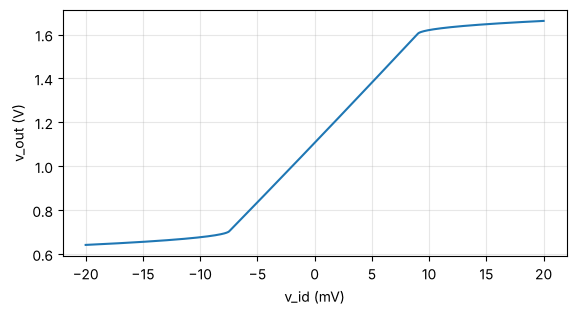

In [3]:
k, lam, VDD, VT0, ITAIL, VIC = 5e-3, 0.1, 1.8, 0.5, 200e-6, 1.2


def ids(vgs, vds, kk=k):
    vov = vgs - VT0
    if vov <= 0: return 0.0
    if vds >= vov: return 0.5 * kk * vov ** 2 * (1 + lam * vds)
    return kk * (vov * vds - vds ** 2 / 2) * (1 + lam * vds)


def ota_dc(vid, m4=1.0, guess=None):
    def f(x):
        vs, va, vo = x
        i1 = ids(VIC + vid / 2 - vs, va - vs); i2 = ids(VIC - vid / 2 - vs, vo - vs)
        i3 = ids(VDD - va, VDD - va); i4 = m4 * ids(VDD - va, VDD - vo)
        return [i1 + i2 - ITAIL, i3 - i1, i4 - i2]
    return fsolve(f, guess if guess is not None else [0.5, 1.1, 1.1], xtol=1e-12)


vids = np.linspace(-0.02, 0.02, 801)
outs, g = [], None
for vd in np.concatenate([vids[400::-1], vids[401:]]):
    g = ota_dc(vd, guess=g); outs.append((vd, g[2]))
outs = sorted(outs)
x = np.array([o[0] for o in outs]); y = np.array([o[1] for o in outs])
bal = ota_dc(0.0)
slope = (ota_dc(1e-5, guess=bal)[2] - ota_dc(-1e-5, guess=bal)[2]) / 2e-5
mis = ota_dc(0.0, m4=1.01, guess=bal)
print(f"balanced output {bal[2]:.4f} V (diode node {bal[1]:.4f} V); slope at balance {abs(slope):.2f}")
print(f"1% extra current in M4 moves the output by {1e3 * (mis[2] - bal[2]):.1f} mV")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(x * 1e3, y); ax.set_xlabel('v_id (mV)'); ax.set_ylabel('v_out (V)'); ax.grid(True, alpha=0.3)
plt.show()

**What to notice.** The high-gain region spans only tens of millivolts of input, and a 1% current mismatch moves the output by tens of millivolts. Open loop, the output level is fixed by mismatch; feedback must set it.

## Part 3 · Gains against tail resistance

The five-transistor OTA of Example 12-02.2 (small-signal, $g_m$ = 1 mA/V, $r_o$ = 100 kΩ) with the tail resistance swept, against the hand estimates $A_d = g_m(r_o \parallel r_o)$ and $A_{cm} \approx 1/(2g_{m3}R_{SS})$.

In [4]:
def ota(v1, v2, RSS):
    el = [('M', 'a', 'g1', 's', gm, ro), ('M', 'out', 'g2', 's', gm, ro), ('M', 'a', 'a', '0', gm, ro),
          ('M', 'out', 'a', '0', gm, ro), ('R', 's', '0', RSS)]
    return solve(['s', 'a', 'out'], el, {'g1': v1, 'g2': v2})['out']


for RSS in (10e3, 50e3, 500e3, 5e6):
    Ad, Acm = abs(ota(0.5, -0.5, RSS)), abs(ota(1, 1, RSS))
    print(f"R_SS = {RSS / 1e3:7.0f} kOhm: A_d {Ad:6.2f} (hand 50.00), A_cm {Acm:.6f} (hand {1 / (2 * gm * RSS):.6f}), "
          f"CMRR {db(Ad / Acm):5.1f} dB")

R_SS =      10 kOhm: A_d  49.74 (hand 50.00), A_cm 0.046681 (hand 0.050000), CMRR  60.6 dB
R_SS =      50 kOhm: A_d  49.75 (hand 50.00), A_cm 0.009706 (hand 0.010000), CMRR  74.2 dB
R_SS =     500 kOhm: A_d  49.75 (hand 50.00), A_cm 0.000979 (hand 0.001000), CMRR  94.1 dB
R_SS =    5000 kOhm: A_d  49.75 (hand 50.00), A_cm 0.000098 (hand 0.000100), CMRR 114.1 dB


**What to notice.** The differential gain barely depends on the tail; the common-mode gain falls in proportion to it, so CMRR rises 20 dB per decade of tail resistance, and the hand estimate tracks the full circuit within a few percent.

## Part 4 · A two-stage amplifier and its input-referred offset

The OTA (full circuit) drives a PMOS common-source stage with $g_m$ = 4 mA/V and $r_o$ = 25 kΩ for both it and its load (Example 12-02.5). An offset at the second stage's input is referred to the amplifier's input by finding the input that nulls the output.

In [5]:
A1 = abs(ota(0.5, -0.5, 50e3))
A2 = abs(solve(['o'], [('M', 'o', 'in', '0', 4e-3, 25e3), ('R', 'o', '0', 25e3)], {'in': 1})['o'])
print(f"first stage {A1:.2f}, second stage {A2:.2f}, total {A1 * A2:.0f} ({db(A1 * A2):.2f} dB)")
vos2 = 10e-3
vin_null = -vos2 / A1
print(f"a 10 mV second-stage offset is {abs(vin_null) * 1e3:.4f} mV at the input")

first stage 49.75, second stage 50.00, total 2488 (67.92 dB)
a 10 mV second-stage offset is 0.2010 mV at the input


**What to take away.** Loads that are stiff to signals but cheap in volts give gain; cascodes multiply it if both sides are cascoded; and stages multiply gains while dividing later offsets by the gain before them. Every high-gain node needs feedback to set its DC level.